SANTIAGO DIE MOREJÓN - 21/03/2026 - IA - Entregable 1 - Visualización de Datos

# Notebook 2: Visualización de Datos
En este notebook visualizaremos los datos del dataset de la competición IA2526 usando `matplotlib` y `seaborn`, con el objetivo de confirmar visualmente las hipótesis planteadas en el notebook de análisis y descubrir nuevas relaciones entre los descriptores y las clases de actividad.

## 1. Carga de datos

Comenzamos instalando la última versión de `seaborn` e importando las librerías necesarias.

In [1]:
!pip install seaborn -Uq

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
# La siguiente línea se utiliza para generar los gráficos en formato SVG los cuales son más legibles.
%config InlineBackend.figure_format = 'svg'

Cargamos los ficheros desde el repositorio público de GitHub DATA_URL.

In [3]:
!wget DATA_URL -O train.csv
!wget DATA_URL  -O test.csv

--2026-03-21 17:30:19--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 336082 (328K) [text/plain]
Saving to: ‘train.csv’

train.csv           100%[===================>] 328.21K  --.-KB/s    in 0.006s  

2026-03-21 17:30:20 (53.1 MB/s) - ‘train.csv’ saved [336082/336082]

--2026-03-21 17:30:21--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 113736 (111K) [text/plain]
Saving to: ‘test.csv’

test.csv            100%[===================>] 111.07K  --.-KB/s    in 0.002s  

2026-03-21 17:30:22 (45.1 MB/s) - ‘test.

In [4]:
traindf = pd.read_csv('train.csv')
testdf  = pd.read_csv('test.csv')
traindf.head()

,SL,EEG,BP,HR,CIRCULATION,ACTIVITY
0,4019.64,-1600.00,13,79,317,3
1,2191.03,-1146.08,20,54,165,2
2,2787.99,-1263.38,46,67,224,2
3,9545.98,-2848.93,26,138,554,4
4,14148.80,-2381.15,85,120,809,4


## 2. Distribución de clases

Antes de visualizar los descriptores, conviene recordar cuántas instancias hay de cada clase de actividad. Un dataset muy desbalanceado puede afectar tanto a la interpretación visual como al entrenamiento del clasificador.

<Axes: xlabel='ACTIVITY', ylabel='count'>

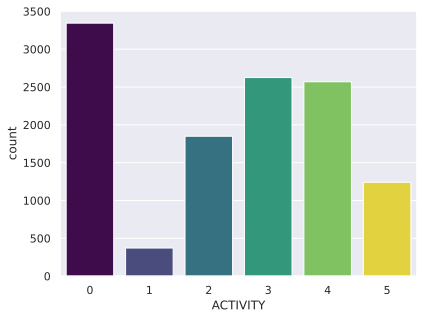

In [5]:
sns.countplot(x='ACTIVITY', hue='ACTIVITY', data=traindf, palette='viridis', legend=False)

Como ya vimos en el anterior notebook el dataset está desbalanceado. La clase 0 es la que mas registros tiene con mas o menos 3300 registros, mientras que la clase 1 es la mas pequeña con solo 370, lo que confirma el 3.09% calculado en el notebook 1. Las clases 3 y 4 son las más similares en números, lo que junto a su solapamiento en descriptores las convierte en las más difíciles de clasificar.

## 3. Visualización univariante

El análisis univariante estudia cada descriptor de forma independiente para entender la distribución de sus valores.

### 3.1 Histogramas

Los histogramas permiten ver la distribución de cada descriptor. Dado que las escalas son muy distintas entre descriptores (como observamos en el notebook 1), es importante visualizarlos por separado.

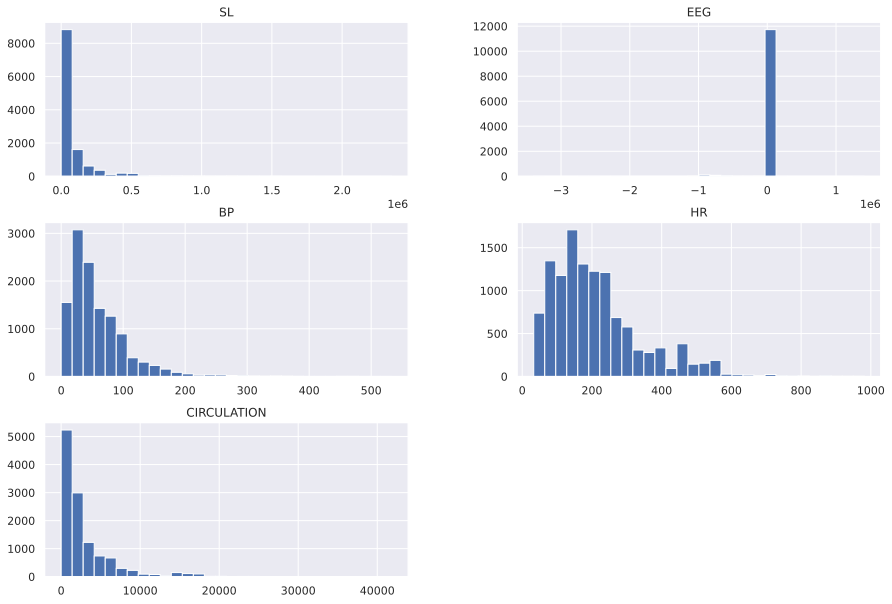

In [6]:
cols = ['SL', 'EEG', 'BP', 'HR', 'CIRCULATION']
traindf[cols].hist(bins=30,figsize=(15, 10));


Como ya se vio en el notebook de analisis de datos

In [7]:
traindf[cols].apply([np.min, np.max])

,SL,EEG,BP,HR,CIRCULATION
min,4.222420e+01,-3396800.0,0,33,5
max,2.352450e+06,1410000.0,533,981,41819


In [8]:
traindf[cols].mean()

,0
SL,75660.224274
EEG,-22291.118884
BP,58.483874
HR,212.415535
CIRCULATION,2900.695058


Los descriptores se desvían poco de su media, lo que indica que la mayoría de las muestras tienen valores similares entre sí. Esto es positivo, ya que significa que el dataset es estable y no hay grandes fluctuaciones.
Dicho esto, cada descriptor tiene su propio comportamiento:

* SL tiene una media de 75,660 pero su máximo llega hasta 2,352,450, lo que confirma que los valores extremos son muy poco frecuentes pero elevan considerablemente la media respecto a lo que se aprecia en el histograma.
* BP y CIRCULATION siguen un patrón similar, con medias bajas (58 y 2,900 respectivamente) que se corresponden bien con sus distribuciones. BP se mueve entre 0 y 533, mientras que CIRCULATION lo hace entre 5 y 41,819.
* HR es el más distribuido de los cinco, con una media de 212 dentro de un rango de 33 a 981, lo que sugiere que la frecuencia cardíaca varía más gradualmente entre actividades.
* Mención especial a EEG, cuya media de -22,291 llama la atención a pesar de que la gran mayoría de sus valores se agrupan en torno a 0. Esto evidencia el peso de sus valores extremos, que van desde -3,396,800 hasta 1,410,000. Estos casos son tan pocos que son invisibles en el histograma.

### 3.2 Gráficos de densidad

Los gráficos de densidad son una versión suavizada del histograma. Son útiles para comparar la distribución de un descriptor entre distintas clases.

In [ ]:
traindf[cols].plot(kind='density', subplots=True, layout=(2, 3),
                   sharex=False, figsize=(15, 10));


Los gráficos de densidad confirman lo visto antes en los histogramas. SL y CIRCULATION tienen un pico muy grande en valores bajos con una cola larga hacia la derecha, lo que como dijimos antes implica que la mayoría de las muestras tienen valores pequeños pero hay casos extremos que son poco frecuentes. EEG muestra una distribución con un pico muy fino y concentrado en el 0 lo que la convierte en el descriptor menos util de las cinco.

### 3.3 Diagramas de caja (Boxplots)

Los boxplots muestran la mediana, los cuartiles y los valores atípicos. Representándolos por clase podemos ver si las distribuciones de cada descriptor difieren según la actividad.

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
for idx, feat in enumerate(cols):
    ax = axes[int(idx / 3), idx % 3]
    sns.boxplot(x='ACTIVITY', hue='ACTIVITY', y=feat, data=traindf, ax=ax, palette='Set2', legend=False)
    ax.set_xlabel('')
    ax.set_ylabel(feat)
fig.tight_layout()


HR y BP son los descriptores más útiles para separar clases, con medianas visiblemente distintas entre actividades. CIRCULATION destaca únicamente para identificar la clase 0, que presenta valores muy superiores al resto. SL y EEG aportan poca información, con clases muy solapadas y medianas similares. En cuanto a outliers, SL y CIRCULATION son los más tienen, con valores extremos muy alejados de la caja, especialmente en la clase 0.

## 4. Visualización bivariante

El análisis bivariante estudia la relación entre pares de descriptores.

### 4.1 Mapa de correlación

El mapa de calor de la matriz de correlación nos muestra qué descriptores están más relacionados entre sí.

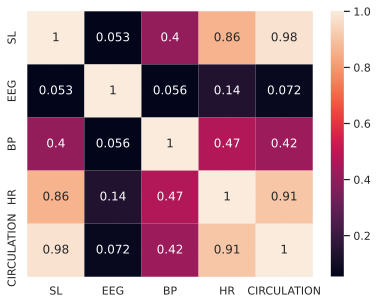

In [11]:
corr_matrix = traindf[cols].corr()
sns.heatmap(corr_matrix, annot=True);

El mapa de correlación revela tres grupos claros.

* SL, HR y CIRCULATION forman un grupo altamente correlacionado entre sí (SL-CIRCULATION: 0.98, HR-CIRCULATION: 0.91, HR-SL: 0.86), lo que significa que hay redundancia de información y posible multicolinealidad en modelos lineales.
* BP muestra correlaciones normales con el primer grupo (0.40-0.47), dandonos información complementaria sin ser redundante.
* EEG es completamente independiente del resto pero como ya vimos antes la variable apenas aporta información útil

### 4.2 Diagramas de dispersión

Los scatter plots permiten ver visualmente si dos descriptores juntos son capaces de separar las clases.

In [ ]:
sns.lmplot(x='HR', y='BP', data=traindf, hue='ACTIVITY', fit_reg=False, palette='viridis')

In [ ]:
sns.lmplot(x='HR', y='CIRCULATION', data=traindf, hue='ACTIVITY', fit_reg=False, palette='viridis')

In [ ]:
sns.lmplot(x='BP', y='EEG', data=traindf, hue='ACTIVITY', fit_reg=False, palette='viridis')

In [ ]:
sns.lmplot(x='BP', y='CIRCULATION', data=traindf, hue='ACTIVITY', fit_reg=False, palette='viridis')

* En BP-CIRCULATION se confirma que la clase 0 tiene los valores altos de ambos ejes pero sin separarse limpiamente del resto.
* EN BP-EEG se confirma que EEG no aporta nada, todos los puntos están aplastados en torno a 0 independientemente de la clase, con solo unos pocos outliers aislados.
* En el par HR-BP no se forman clusters claramente separados, las clases están muy mezcladas aunque la clase 0 tiende a aparecer en valores más altos de HR.
* En HR-CIRCULATION se confirma la alta correlación entre ambas variables (los puntos forman una línea diagonal clara), y aunque la clase 0 vuelve a destacar en los valores más altos, el resto de clases siguen sin separarse de forma limpia.

En general, ningún par forma clusters bien definidos, lo que puede implicar que haga falta combinar varios descriptores.

## 5. Visualización multivariante

El análisis multivariante nos permite estudiar varios descriptores a la vez.

### 5.1 Pairplot

El `pairplot` de seaborn construye automáticamente una matriz de scatter plots para todos los pares de descriptores, coloreando los puntos por clase. Es una forma rápida de detectar qué pares de descriptores separan mejor las clases.

In [ ]:
%config InlineBackend.figure_format = 'png'
sns.pairplot(traindf[cols + ['ACTIVITY']], hue='ACTIVITY', palette='viridis')
%config InlineBackend.figure_format = 'svg'

El pairplot confirma todo lo analizado hasta ahora. La redundancia entre SL, HR y CIRCULATION es evidente, sus scatter plots forman líneas diagonales bastante claras. EEG es el descriptor menos útil, todos sus scatter plots muestran los puntos aplastados en una línea horizontal independientemente de la clase. BP es el descriptor que muestra una nube de puntos más dispersa y heterogénea, lo que lo convierte en el más complementario del grupo. Ninguna combinación de dos descriptores logra separar las clases de forma limpia.

### 5.2 Reducción de dimensionalidad con t-SNE

t-SNE es una técnica de reducción de dimensionalidad no lineal que proyecta los datos en 2D intentando preservar la estructura local. Es útil para visualizar si las clases son separables en el espacio de descriptores completo.

In [29]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

In [30]:
scaler = StandardScaler()
X = scaler.fit_transform(traindf[cols])

In [31]:
tsne = TSNE(n_components=2, random_state=42)
tsne_repr = tsne.fit_transform(X)

In [ ]:
plt.scatter(tsne_repr[:, 0], tsne_repr[:, 1],
            c=traindf['ACTIVITY'].map({0: 'purple', 1: 'orange', 2: 'green', 3: 'red', 4: 'blue', 5: 'yellow'}),
            alpha=.5)


El resultado del t-SNE muestra que las clases están muy mezcladas sin formar grupos claramente separados, lo que confirma que habra dificultad para clasificarlos0.Vemos que no hay ninguna región del espacio donde una sola clase domine de forma limpia. Esto es consistente con todo el análisis anterior.

## 6. Conclusión

<!-- TODO: Resume los hallazgos más importantes de este notebook:
- ¿Qué descriptores son más útiles para clasificar?
- ¿Qué clases son más difíciles de separar visualmente?
- ¿Se confirman las hipótesis del notebook 1?
- ¿Qué implicaciones tienen estos resultados para la elección del clasificador?
-->

Podemos concluir que HR y BP son los descriptores más útiles para clasificar, con distribuciones claramente distintas entre clases y buena complementariedad entre ellos. SL, HR y CIRCULATION son altamente redundantes, por lo que aportan información similar y no es necesario usarlos todos. EEG es inútil, con valores casi constantes independientemente de la clase.

Las clases más difíciles de separar visualmente son las intermedias (2, 3, 4 y 5), que se mezclan en todos los análisis, mientras que la clase 0 es la más identificable por sus valores extremos en varios descriptores. Esto confirma las hipótesis del notebook 1 sobre el desbalanceo del dataset. El t-SNE evidencia que las clases no son linealmente separables, lo que sugiere que el clasificador deberá capturar relaciones no lineales, descartando modelos lineales.